# 02_3. Stability over time and sign check / Стабильность во времени и проверка знака

**EN.** Steps 6–7 of the methodology. A feature is useful for a bank only if its relationship with risk is *stable*: the model is trained on 2013–2015 and applied years later. Two checks:

1. **Population stability (PSI)** — did the distribution of the feature change between train and validation? PSI (population stability index) = Σ (share_val − share_train) · ln(share_val / share_train) over the train WoE bins. < 0.1 stable, 0.1–0.25 moderate, **> 0.25 large shift → the feature is dropped** (rule for borrower, loan, geography, exposure, behaviour and state features).
2. **Macro features** (house prices, unemployment, market rates) move with the calendar by nature, so PSI is not the right test for them. Instead the *relationship* must be stable: the same direction and IV ≥ 0.02 in **every observation year** 2013, 2014, 2015 (train) and 2016, 2017 (validation). If both a raw and a relative version (state minus US) pass, the relative one is kept.
3. **High-cardinality names** (`servicer_name`, `seller_name`): top-20 categories + "other"; dropped if PSI is still above 0.25.
4. **Sign check** — does the observed direction agree with the expectation fixed in 02_1? Direction of a numeric feature = AUC of its raw value − 0.5 on non-missing rows (> 0: higher value = riskier). Effects below 0.01 are treated as "no direction".

**RU.** Шаги 6–7 методологии. Признак полезен банку, только если его связь с риском *устойчива*: модель обучена на 2013–2015 гг., а применяется годы спустя. Проверки:

1. **Стабильность популяции (PSI)** — изменилось ли распределение признака между train и validation? PSI = Σ (доля_val − доля_train) · ln(доля_val / доля_train) по WoE-корзинам train. < 0,1 — стабильно, 0,1–0,25 — умеренный сдвиг, **> 0,25 — сильный сдвиг, признак исключается** (правило для признаков заёмщика, кредита, географии, экспозиции, поведения и состояния).
2. **Макро-признаки** (цены на жильё, безработица, рыночные ставки) по своей природе меняются вместе с календарём, поэтому PSI для них — неправильный тест. Вместо него устойчивой должна быть *связь*: одинаковое направление и IV ≥ 0,02 в **каждом году наблюдения** 2013, 2014, 2015 (train) и 2016, 2017 (validation). Если проходят и исходная, и относительная версия (штат минус США), остаётся относительная.
3. **Названия с множеством значений** (`servicer_name`, `seller_name`): топ-20 категорий + «прочие»; исключаются, если PSI всё равно выше 0,25.
4. **Проверка знака** — совпадает ли фактическое направление с ожиданием из 02_1? Направление числового признака = AUC его исходного значения − 0,5 на непустых строках (> 0 — чем больше значение, тем выше риск). Эффект меньше 0,01 считается «направления нет».

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.data.features import COLUMNS, candidate_features, categorical_features
from xai_ews.features.data import TASKS, load_train, load_validation
from xai_ews.features.rationale import RATIONALE
from xai_ews.features.stability import (categorical_sign_check, macro_stable, psi_binned,
                                        psi_top_categories, sign_check, strength_by_period)
from xai_ews.features.univariate import level_rates, univariate_apply
from xai_ews.features.woe import fit_woe, load_binners
from xai_ews.paths import FEATURE_SELECTION_DIR, STAGE2_INTERIM_DIR

CFG = feature_config()
RULES = CFG["rules"]["stability"]
FEATS = candidate_features()
CATS = set(categorical_features())
MACRO = [f for f in FEATS if COLUMNS[f].temporal == "macro_lagged"]
TOP_N = RULES["high_cardinality_top_n"]
uni = pd.read_csv(FEATURE_SELECTION_DIR / "univariate.csv")
print("macro-rule features:", MACRO)
print(RULES)

macro-rule features: ['mtm_ltv', 'hpi_chg_since_orig', 'hpi_chg_12m', 'unemployment', 'unemployment_chg_6m', 'unemployment_chg_12m', 'unemployment_rel_us', 'unemployment_chg_12m_rel_us', 'hpi_chg_12m_rel_us', 'hpi_chg_since_orig_rel_us', 'rate_spread_pmms']
{'psi_max': 0.25, 'psi_groups': ['borrower', 'loan', 'geography', 'exposure', 'behaviour', 'state_at_t'], 'macro_years': [2013, 2014, 2015, 2016, 2017], 'macro_iv_min_year': 0.02, 'macro_sign_consistent': True, 'prefer_relative_macro': True, 'sign_min_effect': 0.01, 'high_cardinality_top_n': {'servicer_name': 20, 'seller_name': 20}}


### 1. Compute PSI, yearly strength and level rates / Расчёт PSI, силы по годам и долей по уровням

**EN.** Load the Y1 train and validation (population: loans current at the observation date, DPD = 0, and never in default before it; validation with the hurricane flag), compute PSI on the train WoE bins (validation without and with hurricane rows), the IV and direction of macro features in each observation year, event rates of the expected risky / safe levels of categorical features, and the top-20 PSI and IV of servicer and seller names. A few minutes.

**RU.** Загружаем train и validation популяции Y1 (кредиты без просрочки на дату наблюдения, DPD = 0, не бывшие в дефолте до неё; validation — с флагом ураганов), считаем PSI по WoE-корзинам train (validation без ураганов и с ними), IV и направление макро-признаков в каждом году наблюдения, доли событий у ожидаемо рискованного и безопасного уровней категориальных признаков, а также PSI по топ-20 и IV названий сервисера и продавца. Несколько минут.

In [2]:
psi_rows, period_rows, level_rows, name_rows, occ_rows = [], [], [], [], []
for task in TASKS:
    binners = load_binners(STAGE2_INTERIM_DIR / f"woe_binners_{task}.json")
    binners_s = load_binners(STAGE2_INTERIM_DIR / f"woe_binners_{task}_sens.json")   # sensitivity binning
    tr = load_train(task)
    va_all = load_validation(task, hurricanes=True)
    va = va_all.filter(~pl.col("val_hurricane_2017"))
    w_tr, y_tr = tr["sample_weight"].to_numpy(), tr[task].to_numpy()
    for f, b in binners.items():
        psi_rows.append({"feature": f, "task": task,
                         "psi_val": psi_binned(b, tr[f].to_numpy(), w_tr, va[f].to_numpy()),
                         "psi_val_hur": psi_binned(b, tr[f].to_numpy(), w_tr, va_all[f].to_numpy()),
                         "psi_val_sens": psi_binned(binners_s[f], tr[f].to_numpy(), w_tr, va[f].to_numpy())})
    year = np.r_[tr["m"].to_numpy() // 12, va["m"].to_numpy() // 12]
    y = np.r_[y_tr, va[task].to_numpy()]
    w = np.r_[w_tr, va["sample_weight"].to_numpy()]
    state = np.r_[tr["property_state"].to_numpy(), va["property_state"].to_numpy()]
    no_pr = state != "PR"
    year_h = np.r_[tr["m"].to_numpy() // 12, va_all["m"].to_numpy() // 12]
    y_h, w_h = np.r_[y_tr, va_all[task].to_numpy()], np.r_[w_tr, va_all["sample_weight"].to_numpy()]
    for f in MACRO:
        x = np.r_[tr[f].to_numpy(), va[f].to_numpy()]
        period_rows.append(strength_by_period(binners[f], x, y, w, year).assign(task=task, variant="main"))
        period_rows.append(strength_by_period(binners[f], x[no_pr], y[no_pr], w[no_pr], year[no_pr])
                           .assign(task=task, variant="without PR"))
        x_h = np.r_[tr[f].to_numpy(), va_all[f].to_numpy()]
        period_rows.append(strength_by_period(binners[f], x_h, y_h, w_h, year_h).assign(task=task, variant="with hurricane rows"))
    # investors vs principal residence within LTV bands (sign check of occupancy_status)
    for sample, d in [("train", tr), ("val", va)]:
        occ_rows.append(d.with_columns(pl.col("original_loan_to_value_ratio_ltv").cut([60, 70, 80, 90]).alias("ltv_band"))
                        .group_by("occupancy_status", "ltv_band")
                        .agg(pl.col("sample_weight").sum().alias("weight"),
                             ((pl.col(task) * pl.col("sample_weight")).sum() / pl.col("sample_weight").sum()).alias("event_rate"),
                             pl.col(task).sum().alias("events"))
                        .with_columns(pl.lit(task).alias("task"), pl.lit(sample).alias("sample")).to_pandas())
    for f in FEATS:
        r = RATIONALE[f]
        if r.sign == "cat":
            for sample, d, ww in [("train", tr, w_tr), ("val", va, None)]:
                rates = level_rates(d[f].to_numpy(), d[task].to_numpy(),
                                    ww if ww is not None else np.ones(d.height), [r.risky, r.safe])
                level_rows.append({"feature": f, "task": task, "sample": sample, "risky": r.risky, "safe": r.safe,
                                   "rate_risky": rates[r.risky], "rate_safe": rates[r.safe],
                                   "sign_status": categorical_sign_check(rates, r.risky, r.safe)})
    for f, n in TOP_N.items():
        grouped = {}
        for name, d in [("tr", tr), ("va", va)]:
            tops = tr.group_by(f).agg(pl.col("sample_weight").sum()).sort("sample_weight", descending=True)[f].head(n)
            grouped[name] = np.where(d[f].is_in(tops.implode()).to_numpy(), d[f].to_numpy(), "__other__")
        b_top = fit_woe(grouped["tr"], y_tr, w_tr, f, True, CFG["binning"])
        iv_val = univariate_apply(pl.DataFrame({f: grouped["va"], task: va[task], "sample_weight": va["sample_weight"]}),
                                  task, {f: b_top}, "val")[ "iv_val"].iloc[0]
        name_rows.append({"feature": f, "task": task, "categories_train": tr[f].n_unique(),
                          "psi_raw_categories": psi_top_categories(tr[f].to_numpy(), w_tr, va[f].to_numpy(), top=10_000),
                          f"psi_top{n}_plus_other": psi_top_categories(tr[f].to_numpy(), w_tr, va[f].to_numpy(), top=n),
                          "iv_train_top_n": b_top.iv, "iv_val_top_n": iv_val})
    del tr, va, va_all; gc.collect()

psi = pd.DataFrame(psi_rows)
periods = pd.concat(period_rows, ignore_index=True)
levels = pd.DataFrame(level_rows)
names = pd.DataFrame(name_rows)
occ = pd.concat(occ_rows, ignore_index=True)
periods_all = periods
periods = periods_all[periods_all["variant"] == "main"].drop(columns="variant")
print(psi.shape, periods.shape, levels.shape, names.shape)

(59, 5) (55, 8) (24, 8) (2, 7)


### 2. PSI of borrower, loan, geography, exposure, behaviour and state features / PSI немакро-признаков

**EN.** PSI on the train WoE bins. Only features that passed step 2 (IV ≥ 0.02) are shown.

**RU.** PSI по WoE-корзинам train. Показаны только признаки, прошедшие шаг 2 (IV ≥ 0,02).

In [3]:
passed = set(uni.loc[uni["pass_iv"], "feature"])
pw = psi.pivot(index="feature", columns="task", values=["psi_val", "psi_val_hur"])
pw.columns = [f"{a}_{b}" for a, b in pw.columns]
pw["psi_max"] = pw[[f"psi_val_{t}" for t in TASKS]].max(axis=1)
pw["psi_max_hur"] = pw[[f"psi_val_hur_{t}" for t in TASKS]].max(axis=1)
pw["group"] = [COLUMNS[f].group for f in pw.index]
pw["rule"] = np.where(pw.index.isin(MACRO), "macro", np.where(pw.index.isin(list(TOP_N)), "top-N", "psi"))
non_macro = pw[(pw["rule"] == "psi") & pw.index.isin(passed)].sort_values("psi_max", ascending=False)
print(f"PSI > {RULES['psi_max']}: {(non_macro['psi_max'] > RULES['psi_max']).sum()} of {len(non_macro)}; "
      f"0.1-0.25: {non_macro['psi_max'].between(0.1, RULES['psi_max']).sum()}")
non_macro.head(15)[["group", *[f"psi_val_{t}" for t in TASKS], "psi_max", "psi_max_hur"]]

PSI > 0.25: 0 of 31; 0.1-0.25: 3


,group,psi_val_y1,psi_max,psi_max_hur
feature,,,,
age,state_at_t,0.2147,0.2147,0.2007
remaining_months_to_legal_maturity,state_at_t,0.1036,0.1036,0.0993
upb_chg_6m,behaviour,0.1029,0.1029,0.1013
upb_to_orig,exposure,0.0953,0.0953,0.0909
upb_chg_12m,behaviour,0.0886,0.0886,0.0874
remaining_months_to_maturity,state_at_t,0.0858,0.0858,0.0787
loan_purpose,loan,0.0591,0.0591,0.0689
current_interest_rate,state_at_t,0.0571,0.0571,0.0592
original_interest_rate,loan,0.0571,0.0571,0.0592


**EN. How to read.** None of the 31 features that passed step 2 and are checked by PSI (macro and name features have their own rules) exceeds PSI 0.25. Three are in the "moderate" zone 0.1–0.25: loan age (0.21), the remaining term to legal maturity (0.10) and the balance change over 6 months (0.10); balance / original balance, the 12-month balance change and the remaining term are just below 0.1. They all move mechanically with time: validation is 1.5–3 years later, so the same loans are older and more amortised, and newer vintages enter. Credit score, DTI, LTV and the payment-behaviour features are stable (PSI < 0.05). Keeping the hurricane rows hardly changes PSI (last column): the hurricane affects the *outcome*, not the feature distribution. Under the sensitivity binning (bins down to 0.05 %) no PSI decision changes.

**RU. Как читать.** Ни один из 31 признака, прошедших шаг 2 и проверяемых по PSI (для макро-признаков и названий — свои правила), не превышает PSI 0,25. Три в «умеренной» зоне 0,1–0,25: возраст кредита (0,21), остаток срока до юридического погашения (0,10) и изменение ОД за 6 мес. (0,10); ОД / исходный ОД, изменение ОД за 12 мес. и остаток срока чуть ниже 0,1. Все они механически меняются со временем: validation на 1,5–3 года позже, те же кредиты старше и сильнее погашены, добавляются новые поколения. Рейтинг, DTI, LTV и признаки платёжного поведения стабильны (PSI < 0,05). Если оставить наблюдения с ураганами, PSI почти не меняется (последняя колонка): ураган влияет на *исход*, а не на распределение признака. При биннинге проверки чувствительности (корзины до 0,05 %) ни одно решение по PSI не меняется.

### 3. Servicer and seller names: top-20 + "other" / Названия сервисера и продавца: топ-20 + «прочие»

**EN.** Fannie Mae already groups small institutions into "Other". We keep the 20 largest categories by train weight, everything else becomes "other", and recompute PSI and IV. `psi_raw_categories` is PSI over all categories for comparison.

**RU.** Fannie Mae уже объединяет мелкие организации в «Other». Оставляем 20 крупнейших категорий по весу в train, остальное — «прочие», и пересчитываем PSI и IV. `psi_raw_categories` — PSI по всем категориям для сравнения.

In [4]:
names

,feature,task,categories_train,psi_raw_categories,psi_top20_plus_other,iv_train_top_n,iv_val_top_n
0,servicer_name,y1,29,0.8062,0.5411,0.0268,0.0482
1,seller_name,y1,39,0.4313,0.2406,0.0442,0.0494


**EN. Conclusion.** `servicer_name` shifts strongly even after grouping: PSI 0.81 over all categories and **0.54 with top-20 + other** — servicing rights are sold between companies, so the servicer mix of the same loans changes over time. Its IV is also small (0.03 on train). → **excluded**. `seller_name` shifts less: 0.43 over all categories, **0.24 with top-20 + other** — just below the limit; IV 0.04 on train, 0.05 on validation. → **kept as top-20 + "other"** (the grouping is fitted on train and stored in `configs/features.yaml`). Being only 0.01 below the threshold, it is a borderline case; the model-importance step will show whether it adds anything.

**RU. Вывод.** `servicer_name` сильно сдвигается даже после группировки: PSI 0,81 по всем категориям и **0,54 по топ-20 + «прочие»** — права на обслуживание продаются между компаниями, и состав сервисеров у тех же кредитов меняется со временем. IV у него тоже мал (0,03 на train). → **исключается**. `seller_name` сдвигается меньше: 0,43 по всем категориям, **0,24 по топ-20 + «прочие»** — чуть ниже порога; IV 0,04 на train, 0,05 на validation. → **остаётся в виде топ-20 + «прочие»** (группировка обучена на train и записана в `configs/features.yaml`). Он всего на 0,01 ниже порога — пограничный случай; шаг важности в модели покажет, добавляет ли он что-нибудь.

### 4. Macro features: direction and strength by year / Макро-признаки: направление и сила по годам

**EN.** For each macro feature and observation year: IV (with the train bins) and the direction (AUC − 0.5). Rule: stable = IV ≥ 0.02 in every year **and** the same direction in every year.

**RU.** Для каждого макро-признака и года наблюдения: IV (с корзинами train) и направление (AUC − 0,5). Правило: устойчив = IV ≥ 0,02 в каждом году **и** одинаковое направление во всех годах.

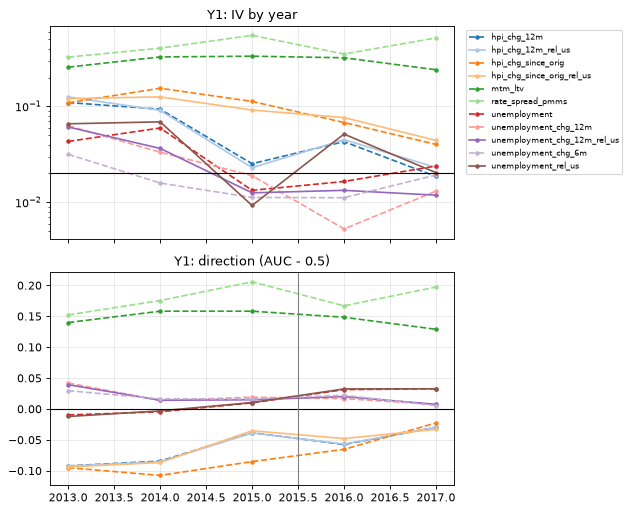

In [5]:
fig, axes = plt.subplots(2, len(TASKS), figsize=(5.5 * len(TASKS) + 2.5, 6.5), sharex=True, squeeze=False)
colors = dict(zip(sorted(MACRO), plt.get_cmap("tab20").colors))
for j, task in enumerate(TASKS):
    d = periods[periods["task"] == task]
    for f, g in d.groupby("feature"):
        ls = "-" if f.endswith("_rel_us") else "--"
        axes[0, j].plot(g["period"], g["iv"], ls, marker="o", ms=3, label=f, color=colors[f])
        axes[1, j].plot(g["period"], g["direction"], ls, marker="o", ms=3, label=f, color=colors[f])
    axes[0, j].axhline(RULES["macro_iv_min_year"], c="k", lw=1); axes[0, j].set_yscale("log")
    axes[0, j].set_title(f"{task.upper()}: IV by year"); axes[1, j].set_title(f"{task.upper()}: direction (AUC - 0.5)")
    axes[1, j].axhline(0, c="k", lw=1); axes[1, j].axvline(2015.5, c="grey", lw=1)
axes[0, -1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [6]:
mst = []
for (f, task), g in periods.groupby(["feature", "task"]):
    r = macro_stable(g.sort_values("period"), RULES["macro_iv_min_year"], RULES["sign_min_effect"])
    iv_tr = uni.query("feature == @f and task == @task")["iv_train"].iloc[0]
    mst.append({**r, "task": task, "iv_train": iv_tr, "passes_iv": iv_tr >= CFG["rules"]["univariate"]["iv_min"],
                "directions": " ".join(f"{v:+.3f}" for v in g.sort_values("period")["direction"])})
mst = pd.DataFrame(mst)
macro_dec = mst[mst["passes_iv"]].groupby("feature")["stable"].any().reindex(MACRO).fillna(False)
mst.sort_values(["feature", "task"]).set_index(["feature", "task"])[
    ["iv_train", "iv_min_period", "iv_max_period", "sign_consistent", "strength_ok", "stable", "directions"]]

,,iv_train,iv_min_period,iv_max_period,sign_consistent,strength_ok,stable,directions
feature,task,,,,,,,
hpi_chg_12m,y1,0.0439,0.0186,0.1097,True,False,False,-0.092 -0.084 -0.038 -0.057 -0.030
hpi_chg_12m_rel_us,y1,0.0651,0.0230,0.1257,True,True,True,-0.092 -0.086 -0.039 -0.057 -0.030
hpi_chg_since_orig,y1,0.0944,0.0402,0.1546,True,True,True,-0.095 -0.108 -0.085 -0.065 -0.023
hpi_chg_since_orig_rel_us,y1,0.0891,0.0442,0.1258,True,True,True,-0.094 -0.087 -0.035 -0.048 -0.033
mtm_ltv,y1,0.3103,0.2411,0.3337,True,True,True,+0.140 +0.158 +0.158 +0.148 +0.129
rate_spread_pmms,y1,0.4616,0.3264,0.5504,True,True,True,+0.152 +0.175 +0.206 +0.167 +0.197
unemployment,y1,0.0227,0.0133,0.0595,False,False,False,-0.010 -0.005 +0.010 +0.031 +0.033
unemployment_chg_12m,y1,0.0293,0.0053,0.0629,False,False,False,+0.042 +0.014 +0.019 +0.017 +0.007
unemployment_chg_12m_rel_us,y1,0.0218,0.0119,0.0610,False,False,False,+0.039 +0.014 +0.015 +0.020 +0.007


**EN. How to read and conclusion.**
- **Collateral and rates are very stable:** `mtm_ltv` (IV 0.24–0.33 every year, direction +0.13…+0.16) and `rate_spread_pmms` (IV 0.33–0.55, +0.15…+0.21) keep the same strong relationship in all five years → kept.
- **House prices:** both relative versions (local minus US) are stable: negative direction and IV ≥ 0.02 in every year (the 12-month one only just: IV 0.023 in 2015 and 2017). The raw change since origination passes too, although its direction fades from −0.10…−0.11 in 2013–2014 to −0.02 in 2017 (prices rose everywhere, so the raw change increasingly tracks the calendar); by the rule its **relative version is kept** and the raw one dropped. The raw 12-month change keeps its direction, but its IV falls to 0.019 in 2017, below 0.02 → not stable, dropped; its relative version stays.
- **Unemployment fails completely.** The level (raw and relative to the US) has a *negative* direction in 2013–2014 (higher unemployment → fewer defaults, against the prior) and a positive one in 2016–2017; its IV also drops below 0.02 in some years. The 12-month changes keep a positive sign, but in 2017 the effect is only 0.007 (below the 0.01 "no direction" cut) and their IV is 0.005–0.013 in 2016–2017 (the 6-month change already failed step 2). In 2013–2014 high-unemployment states were the ones recovering fastest after the crisis, so the cross-section of states does not carry a stable "unemployment → default" link in calm years. Section 4a checks whether this is an artefact of the hurricanes or of Puerto Rico.

**RU. Как читать и вывод.**
- **Залог и ставки очень стабильны:** `mtm_ltv` (IV 0,24–0,33 каждый год, направление +0,13…+0,16) и `rate_spread_pmms` (IV 0,33–0,55, +0,15…+0,21) сохраняют одинаково сильную связь все пять лет → остаются.
- **Цены на жильё:** обе относительные версии (локально минус США) устойчивы: отрицательное направление и IV ≥ 0,02 в каждом году (версия за 12 мес. — впритык: IV 0,023 в 2015 и 2017 гг.). Исходное изменение с даты выдачи тоже проходит, хотя его направление слабеет с −0,10…−0,11 в 2013–2014 гг. до −0,02 в 2017 г. (цены росли везде, и исходное изменение всё больше отражает календарь); по правилу **остаётся относительная версия**, исходная исключается. Исходное изменение за 12 мес. сохраняет направление, но его IV в 2017 г. падает до 0,019, ниже 0,02 → неустойчиво, исключается; его относительная версия остаётся.
- **Безработица не проходит совсем.** Уровень (исходный и относительно США) в 2013–2014 гг. имеет *отрицательное* направление (выше безработица — меньше дефолтов, против ожидания), а в 2016–2017 — положительное; кроме того, в отдельные годы его IV ниже 0,02. Изменения за 12 мес. сохраняют положительный знак, но в 2017 г. эффект всего 0,007 (ниже порога «направления нет» 0,01), а IV в 2016–2017 гг. 0,005–0,013 (изменение за 6 мес. не прошло уже шаг 2). В 2013–2014 гг. штаты с высокой безработицей быстрее всего восстанавливались после кризиса, поэтому в спокойные годы сравнение штатов не даёт устойчивой связи «безработица → дефолт». Раздел 4a проверяет, не артефакт ли это ураганов или Пуэрто-Рико.

### 4a. Unemployment: is the sign flip caused by the hurricanes or by Puerto Rico? / Безработица: не ураганы ли и не Пуэрто-Рико ли дают смену знака?

**EN.** Three variants of the yearly direction and IV of the unemployment features: **main** (as above: validation already *without* the `val_hurricane_2017` rows; train has no hurricane rows); **without PR** — Puerto Rico removed from train and validation entirely (the highest unemployment and ~6 % defaults after hurricane Maria); **with hurricane rows** — for contrast. Rule agreed for this check: if the direction of the *relative* version (state − US) is stable across all five years in the main variant or without PR, the relative version is brought back (its yearly IV is reported); otherwise the exclusion stays.

**RU.** Три варианта направления и IV признаков безработицы по годам: **основной** (как выше: validation уже *без* наблюдений `val_hurricane_2017`; в train наблюдений урагана нет); **без PR** — Пуэрто-Рико убрано из train и validation целиком (самая высокая безработица и ~6 % дефолтов после урагана Мария); **с наблюдениями урагана** — для контраста. Правило, согласованное для этой проверки: если направление *относительной* версии (штат − США) устойчиво во всех пяти годах в основном варианте или без PR, относительная версия возвращается (её IV по годам приводится); иначе исключение остаётся.

In [7]:
UNEMP = [f for f in MACRO if f.startswith("unemployment")]
u = periods_all[periods_all["feature"].isin(UNEMP)]
tab = u.pivot_table(index=["feature", "task", "variant"], columns="period", values="direction").round(3)
tab_iv = u.pivot_table(index=["feature", "task", "variant"], columns="period", values="iv").round(3)
display(tab)
display(tab_iv)

period                                                  2013    2014   2015   2016   2017
feature                     task variant                                                 
unemployment                y1   main                -0.0100 -0.0050 0.0100 0.0310 0.0330
                                 with hurricane rows -0.0100 -0.0050 0.0100 0.0200 0.0390
                                 without PR          -0.0180 -0.0130 0.0070 0.0300 0.0330
unemployment_chg_12m        y1   main                 0.0420  0.0140 0.0190 0.0170 0.0070
                                 with hurricane rows  0.0420  0.0140 0.0190 0.0610 0.1170
                                 without PR           0.0390  0.0100 0.0230 0.0170 0.0070
unemployment_chg_12m_rel_us y1   main                 0.0390  0.0140 0.0150 0.0200 0.0070
                                 with hurricane rows  0.0390  0.0140 0.0150 0.0440 0.1170
                                 without PR           0.0360  0.0100 0.0190 0.0200 0.0070
unemployment_chg_6m         y1   main                 0.0300  0.0160 0.0160 0.0220 0.0050
                                 with hurricane rows  0.0300  0.0160 0.0160 0.0730 0.0980
                                 without PR           0.0250  0.0150 0.0200 0.0220 0.0050
unemployment_rel_us         y1   main                -0.0120 -0.0030 0.0100 0.0320 0.0330
                                 with hurricane rows -0.0120 -0.0030 0.0100 0.0380 0.0390
                                 without PR          -0.0200 -0.0110 0.0070 0.0310 0.0330

period                                                 2013   2014   2015   2016   2017
feature                     task variant                                               
unemployment                y1   main                0.0430 0.0600 0.0130 0.0160 0.0240
                                 with hurricane rows 0.0430 0.0600 0.0130 0.3300 0.8350
                                 without PR          0.0570 0.0350 0.0060 0.0140 0.0240
unemployment_chg_12m        y1   main                0.0630 0.0330 0.0190 0.0050 0.0130
                                 with hurricane rows 0.0630 0.0330 0.0190 0.0460 0.1790
                                 without PR          0.0580 0.0280 0.0170 0.0050 0.0130
unemployment_chg_12m_rel_us y1   main                0.0610 0.0370 0.0130 0.0130 0.0120
                                 with hurricane rows 0.0610 0.0370 0.0130 0.0830 0.2850
                                 without PR          0.0630 0.0300 0.0120 0.0140 0.0120
unemployment_chg_6m         y1   main                0.0320 0.0160 0.0110 0.0110 0.0190
                                 with hurricane rows 0.0320 0.0160 0.0110 0.1030 0.5540
                                 without PR          0.0310 0.0120 0.0110 0.0110 0.0190
unemployment_rel_us         y1   main                0.0660 0.0690 0.0090 0.0510 0.0200
                                 with hurricane rows 0.0660 0.0690 0.0090 0.1980 0.5970
                                 without PR          0.0750 0.0550 0.0060 0.0510 0.0200

In [8]:
pr_share = {}
for task in TASKS:
    v = load_validation(task, ["property_state"], hurricanes=True)
    pr = v.filter(pl.col("property_state") == "PR")
    pr_share[task] = {"PR rows": pr.height, "PR event rate": float(pr[task].mean()),
                      "PR rows flagged as hurricane": int(pr["val_hurricane_2017"].sum())}
    del v
print(pd.DataFrame(pr_share))
unemp_chk = []
for (f, task, variant), g in u.groupby(["feature", "task", "variant"]):
    r = macro_stable(g.sort_values("period"), RULES["macro_iv_min_year"], RULES["sign_min_effect"])
    passes = uni.query("feature == @f and task == @task")["iv_train"].iloc[0] >= CFG["rules"]["univariate"]["iv_min"]
    unemp_chk.append({**r, "task": task, "variant": variant, "passes_iv": passes})
unemp_chk = pd.DataFrame(unemp_chk)
RETURNED_UNEMP = sorted(unemp_chk.query("feature.str.endswith('_rel_us') and passes_iv and sign_consistent "
                                        "and variant in ['main', 'without PR']", engine="python")["feature"].unique())
print("relative unemployment features brought back:", RETURNED_UNEMP)
unemp_chk.set_index(["feature", "task", "variant"])[["sign_consistent", "strength_ok", "iv_min_period", "passes_iv"]]

                                     y1
PR rows                      7,636.0000
PR event rate                    0.0559
PR rows flagged as hurricane 4,017.0000
relative unemployment features brought back: []


sign_consistent  strength_ok  iv_min_period  passes_iv
feature                     task variant                                                                    
unemployment                y1   main                           False        False         0.0133       True
                                 with hurricane rows            False        False         0.0133       True
                                 without PR                     False        False         0.0064       True
unemployment_chg_12m        y1   main                           False        False         0.0053       True
                                 with hurricane rows             True        False         0.0190       True
                                 without PR                     False        False         0.0054       True
unemployment_chg_12m_rel_us y1   main                           False        False         0.0119       True
                                 with hurricane rows             True        False         0.0126       True
                                 without PR                     False        False         0.0115       True
unemployment_chg_6m         y1   main                           False        False         0.0112      False
                                 with hurricane rows             True        False         0.0112      False
                                 without PR                     False        False         0.0106      False
unemployment_rel_us         y1   main                           False        False         0.0093       True
                                 with hurricane rows            False        False         0.0093       True
                                 without PR                     False        False         0.0059       True

**EN. Conclusion.**
- **The hurricane rows are not the cause.** They were already excluded in the main variant; putting them back makes unemployment look *much* stronger in 2016–2017 (IV of the level jumps to 0.33 in 2016 and 0.84 in 2017, of the relative level to 0.20 and 0.60), which is exactly why these rows are removed.
- **Puerto Rico is not the cause either.** PR has the highest unemployment and an event rate of about 6 % in validation, but removing it entirely makes the 2013–2014 reversal *stronger*, not weaker: the direction of the level falls from −0.010 to −0.018 (2013) and from −0.005 to −0.013 (2014), of the relative level from −0.012 to −0.020 (2013). A possible explanation: in 2013–2014 unemployment was highest in the states hit hardest by the crisis, where at the same time house prices were recovering fastest and the loans were "clean" post-crisis originations with strict underwriting — so a higher level went with *fewer* defaults.
- **Relative versions:** the level relative to the US flips sign (− in 2013–2014, + in 2016–2017) in every variant. The 12-month change relative to the US keeps a positive sign in all five years, but in 2017 the effect is 0.007 — below the pre-set 0.01 "no direction" cut — and its IV is 0.013 and 0.012 in 2016–2017, below 0.02. By the rule fixed in advance its direction is not stable; the threshold was set before the results, so the feature is **not** brought back after seeing them. Unemployment is checked instead through a variant with unemployment in the COVID stress test.
- **Decision:** no unemployment feature is brought back. **Limitation:** at the state level the labour-market channel is not identifiable in the calm years 2013–2017. **For stage 3:** in the COVID stress test (2019-03…2021-12), compare the selected model with a variant **"selected + unemployment"** (`unemployment_rel_us`, `unemployment_chg_12m_rel_us`) — unemployment may matter exactly when it moves sharply.

**RU. Вывод.**
- **Ураганы — не причина.** В основном варианте их наблюдения уже исключены; если вернуть их, безработица в 2016–2017 гг. выглядит *намного* сильнее (IV уровня подскакивает до 0,33 в 2016 г. и 0,84 в 2017 г., относительного уровня — до 0,20 и 0,60) — именно поэтому эти строки исключаются.
- **Пуэрто-Рико — тоже не причина.** У PR самая высокая безработица и доля событий около 6 % на validation, но если убрать его целиком, обратный знак 2013–2014 гг. становится *сильнее*, а не слабее: направление уровня падает с −0,010 до −0,018 (2013) и с −0,005 до −0,013 (2014), относительного уровня — с −0,012 до −0,020 (2013). Возможное объяснение: в 2013–2014 гг. безработица была выше всего в штатах, сильнее всего пострадавших от кризиса, где одновременно быстро росли цены на жильё и выдавались «чистые» послекризисные кредиты со строгим андеррайтингом, — поэтому более высокий уровень шёл вместе с *меньшим* числом дефолтов.
- **Относительные версии:** уровень относительно США меняет знак (− в 2013–2014, + в 2016–2017) во всех вариантах. Изменение за 12 мес. относительно США сохраняет положительный знак все пять лет, но в 2017 г. эффект 0,007 — ниже заранее заданного порога «направления нет» 0,01, а IV в 2016–2017 гг. 0,013 и 0,012, ниже 0,02. По правилу, зафиксированному заранее, его направление неустойчиво; порог задан до результатов, поэтому возвращать признак после их просмотра нельзя. Безработица вместо этого проверяется через вариант с безработицей в стресс-тесте COVID.
- **Решение:** ни один признак безработицы не возвращается. **Ограничение:** на уровне штатов канал рынка труда в спокойные 2013–2017 гг. не выделяется. **На этап 3:** в стресс-тесте COVID (2019-03…2021-12) сравнить отобранную модель с вариантом **«отобранные + безработица»** (`unemployment_rel_us`, `unemployment_chg_12m_rel_us`): безработица может быть важна именно тогда, когда она резко меняется.

### 5. Sign check / Проверка знака

**EN.** Observed direction on train and on validation versus the expected sign from 02_1. Status: `match`, `mismatch`, `weak` (|AUC − 0.5| < 0.01), `no prior`. For categorical features: is the event rate of the `risky` level higher than of the `safe` level? Only features that passed step 2 are shown.

**RU.** Фактическое направление на train и на validation против ожидаемого знака из 02_1. Статус: `match` (совпадает), `mismatch` (не совпадает), `weak` (|AUC − 0,5| < 0,01), `no prior` (знак не задан). Для категориальных: выше ли доля событий у уровня `risky`, чем у `safe`? Показаны только признаки, прошедшие шаг 2.

In [9]:
rows = []
for _, u in uni[uni["feature"].isin(passed)].iterrows():
    r = RATIONALE[u["feature"]]
    if r.sign in {"+", "-"}:
        rows.append({"feature": u["feature"], "task": u["task"], "expected": r.sign, "iv_train": u["iv_train"],
                     "dir_train": u["direction_train"], "dir_val": u["direction_val"],
                     "status_train": sign_check(r.sign, u["direction_train"], RULES["sign_min_effect"]),
                     "status_val": sign_check(r.sign, u["direction_val"], RULES["sign_min_effect"])})
signs = pd.DataFrame(rows)
relevant = signs["iv_train"] >= CFG["rules"]["univariate"]["iv_min"]
print("numeric features with a prior, by status on train (tasks with IV >= 0.02):")
print(signs[relevant]["status_train"].value_counts().to_string())
signs[relevant & ((signs["status_train"] != "match") | (signs["status_val"] != "match"))].sort_values("feature")

numeric features with a prior, by status on train (tasks with IV >= 0.02):
status_train
match       27
mismatch     2
weak         1


,feature,task,expected,iv_train,dir_train,dir_val,status_train,status_val
10,age,y1,+,0.0277,-0.0387,-0.0274,mismatch,mismatch
18,excess_principal_12m,y1,-,0.1682,-0.0178,-0.0005,match,weak
15,n_curtail_12m,y1,-,0.2079,-0.0142,-0.0006,match,weak
14,n_curtail_6m,y1,-,0.2128,-0.0137,-0.0031,match,weak
22,unemployment,y1,+,0.0227,-0.0279,0.0280,mismatch,match
24,unemployment_rel_us,y1,+,0.0531,-0.0049,0.0304,weak,match


In [10]:
lv = levels.pivot_table(index=["feature", "risky", "safe"], columns=["task", "sample"],
                        values=["rate_risky", "rate_safe"])
status = levels.pivot_table(index="feature", columns=["task", "sample"], values="sign_status", aggfunc="first")
display(status)
lv.loc[[f for f in lv.index.get_level_values(0) if f in passed]].round(4)

task                                                          y1              
sample                                                     train           val
feature                                                                       
amortization_type                                   level absent  level absent
channel                                                 mismatch      mismatch
first_time_home_buyer_indicator                            match         match
high_loan_to_value_hltv_refinance_option_indicator  level absent  level absent
interest_only_loan_indicator                        level absent  level absent
loan_purpose                                               match         match
mortgage_insurance_type                                    match         match
occupancy_status                                        mismatch      mismatch
prepayment_penalty_indicator                        level absent  level absent
property_type                                              match         match
relocation_mortgage_indicator                              match         match
special_eligibility_program                         level absent         match

rate_risky        rate_safe       
task                                               y1               y1       
sample                                          train    val     train    val
feature                         risky safe                                   
first_time_home_buyer_indicator Y     N        0.0020 0.0031    0.0011 0.0018
loan_purpose                    C     P        0.0017 0.0025    0.0015 0.0023
mortgage_insurance_type         1     NA       0.0023 0.0034    0.0010 0.0016
occupancy_status                I     P        0.0007 0.0010    0.0013 0.0021
property_type                   MH    SF       0.0027 0.0026    0.0013 0.0021

In [11]:
o = occ[occ["occupancy_status"].isin(["I", "P"])].pivot_table(index=["task", "sample", "ltv_band"], columns="occupancy_status",
                                                             values=["event_rate", "events"], observed=True)
o.columns = [f"{a}_{b}" for a, b in o.columns]
o["I_minus_P_pp"] = 100 * (o["event_rate_I"] - o["event_rate_P"])
print("investor (I) vs principal residence (P) by original LTV band:")
o.round(4)

investor (I) vs principal residence (P) by original LTV band:


event_rate_I  event_rate_P  events_I   events_P  I_minus_P_pp
task sample ltv_band                                                                 
y1   train  (-inf, 60]        0.0006        0.0006  120.0000 1,650.0000       -0.0013
            (60, 70]          0.0008        0.0011  145.0000 1,500.0000       -0.0309
            (70, 80]          0.0007        0.0014  433.0000 5,614.0000       -0.0675
            (80, 90]          0.0029        0.0020    8.0000 1,678.0000        0.0907
            (90, inf]         0.0000        0.0024    0.0000 2,448.0000       -0.2398
     val    (-inf, 60]        0.0005        0.0009   19.0000   305.0000       -0.0359
            (60, 70]          0.0012        0.0019   38.0000   391.0000       -0.0752
            (70, 80]          0.0012        0.0020  111.0000 1,254.0000       -0.0866
            (80, 90]          0.0000        0.0026    0.0000   450.0000       -0.2562
            (90, inf]         0.0000        0.0038    0.0000 1,034.0000       -0.3842

**EN. How to read.** 27 of the 30 numeric features with a prior and IV ≥ 0.02 match the expected sign on train (2 mismatch: `age`, `unemployment`; 1 weak: `unemployment_rel_us`); of the categorical ones only `occupancy_status` disagrees among those that passed step 2. The rest:
1. **`n_curtail_6m`, `n_curtail_12m`, `excess_principal_12m`: weak direction on validation despite a large IV (0.17–0.21).** The direction is −0.014…−0.018 on train (just past the 0.01 cut) and close to zero on validation, so the relationship is strong but not monotone. Being current at t does not exclude a delinquency earlier in the last 12 months: when such a loan catches up, the missed instalments show up as principal above schedule, so 1–2 "curtailments" can mark a recently troubled loan rather than a strong one. The WoE bins show it on train: no curtailment 0.12 %, 1–2 months of 6 with extra principal 0.18–0.20 % (riskier than none), 4 or more months 0.02–0.04 % (the safest); validation has the same shape. The mix is an interaction that CatBoost and the WoE bins capture. → **kept**, note in the table.
2. **`age` (loan age): mismatch** on train (−0.039) and on validation (−0.027): older loans are slightly safer, against the prior `+`. The WoE bins are not monotone: on train the event rate peaks early (0.17 % at 9–10 months) and is about 0.10 % at 22–34 months; on validation it rises from 0.19 % up to 9 months to 0.26–0.27 % at 24–32 months and falls to 0.12 % after 34 months. This is the known hump shape of the mortgage default hazard in loan age: the risk grows in the first years and falls afterwards, so a single expected sign does not fit. In addition, a loan that has stayed current and out of default for longer has proven itself (loans that defaulted earlier have left the population). The signal is weak (IV 0.03). → **kept** (`SIGN_REVIEW`), described with its observed direction; **flagged for the supervisor**.
3. **`occupancy_status`: investor (I) loans are *safer* than principal residences (P)**, on train (0.07 % vs 0.13 %) and on validation (0.10 % vs 0.21 %). After 2009 Fannie Mae required more from investor loans (reserves, lower LTV, risk-based price add-ons), so the investors who got a loan are a selected, stronger group. The direction is the same on train and validation, so it is not noise or an error. **By LTV band** (last table): investors almost never have LTV > 80 (8 and 0 Y1 events on train, none on validation), so part of the effect is composition; but within LTV ≤ 80 investors are as safe or safer in every band (70–80: 0.07 % vs 0.14 % on train, 0.12 % vs 0.20 % on validation). The earlier run on the wider population also found investors safer within every FICO band; that breakdown is not repeated here. → **kept**; **question for the supervisor**: accept a reason code "investor property lowers risk", which is counter-intuitive for a banker, or constrain the sign in the scorecard?
4. `unemployment` / `unemployment_rel_us`: the sign flips between train and validation — already excluded by the macro rule.
5. `channel` (mismatch on train) was already removed at step 2 (IV 0.005).

**RU. Как читать.** 27 из 30 числовых признаков с заданным знаком и IV ≥ 0,02 совпадают с ожиданием на train (2 — несовпадение: `age`, `unemployment`; 1 — слабый знак: `unemployment_rel_us`); среди категориальных, прошедших шаг 2, расходится только `occupancy_status`. Остальные:
1. **`n_curtail_6m`, `n_curtail_12m`, `excess_principal_12m`: слабое направление на validation при большом IV (0,17–0,21).** Направление −0,014…−0,018 на train (чуть выше порога 0,01) и близко к нулю на validation: связь сильная, но не монотонная. Отсутствие просрочки на дату t не исключает просрочки раньше в течение последних 12 мес.: когда такой кредит догоняет график, погашение пропущенных взносов выглядит как сверхплановое погашение долга, и 1–2 «частичных досрочных погашения» могут означать недавно проблемный кредит, а не сильного заёмщика. Корзины WoE показывают это на train: без досрочных погашений 0,12 %, 1–2 месяца из 6 с переплатой 0,18–0,20 % (рискованнее, чем без них), 4 месяца и больше 0,02–0,04 % (самые надёжные); на validation форма та же. Смешение — взаимодействие, которое улавливают CatBoost и WoE-корзины. → **остаются**, с пометкой в таблице.
2. **`age` (возраст кредита): несовпадение** на train (−0,039) и на validation (−0,027): более старые кредиты немного безопаснее, против ожидаемого знака `+`. Корзины WoE не монотонны: на train доля событий выше всего рано (0,17 % в 9–10 месяцев) и около 0,10 % в 22–34 месяца; на validation она растёт с 0,19 % до 9 месяцев до 0,26–0,27 % в 24–32 месяца и падает до 0,12 % после 34 месяцев. Это известная «горбатая» форма риска дефолта ипотеки по возрасту кредита: в первые годы риск растёт, потом снижается, поэтому один ожидаемый знак здесь не подходит. Кроме того, кредит, который дольше платит вовремя и не уходил в дефолт, уже показал свою надёжность (кредиты, бывшие в дефолте раньше, из популяции ушли). Сигнал слабый (IV 0,03). → **остаётся** (`SIGN_REVIEW`) и описывается с фактическим направлением; **отмечен для руководителя**.
3. **`occupancy_status`: инвестиционные кредиты (I) *безопаснее* основного жилья (P)** на train (0,07 % против 0,13 %) и на validation (0,10 % против 0,21 %). После 2009 г. Fannie Mae требовала от инвестиционных кредитов больше (резервы, ниже LTV, надбавки к цене за риск), поэтому инвесторы, получившие кредит, — отобранная, более сильная группа. Направление одинаково на train и validation, значит, это не шум и не ошибка. **По полосам LTV** (последняя таблица): у инвесторов почти не бывает LTV > 80 (8 и 0 событий Y1 на train, ни одного на validation), так что часть эффекта — состав; но и при LTV ≤ 80 инвесторы в каждой полосе не хуже или безопаснее (70–80: 0,07 % против 0,14 % на train, 0,12 % против 0,20 % на validation). Предыдущий прогон на более широкой популяции показал, что инвесторы безопаснее и в каждой полосе FICO; здесь эта разбивка не повторяется. → **остаётся**; **вопрос руководителю:** принять reason code «инвестиционный объект снижает риск», контринтуитивный для банкира, или ограничить знак в скоринговой карте?
4. `unemployment` / `unemployment_rel_us`: знак меняется между train и validation — уже исключены правилом для макро.
5. `channel` (несовпадение на train) исключён ещё на шаге 2 (IV 0,005).

### 6. Decisions of steps 6–7 / Решения шагов 6–7

**EN.** The rules applied in order to the features that passed step 2; the reasons are kept for the final table. Sign-check outcomes need a judgement, so they are listed explicitly in `SIGN_REVIEW` with the reason from the analysis above.

**RU.** Правила применяются по порядку к признакам, прошедшим шаг 2; причины сохраняются для итоговой таблицы. Результат проверки знака требует суждения, поэтому он записан явно в `SIGN_REVIEW` с причиной из анализа выше.

In [12]:
# Sign-check decisions (section 5): feature -> ("keep" | "drop", reason)
SIGN_REVIEW = {
    "n_curtail_6m": ("keep", "Y1 non-monotone: 1-2 months of extra principal (often catch-up after a recent "
                             "missed payment) are riskier, regular curtailment (4+ of 6 months) is the safest"),
    "n_curtail_12m": ("keep", "as n_curtail_6m"),
    "excess_principal_12m": ("keep", "as n_curtail_6m"),
    "occupancy_status": ("keep", "investor safer than principal residence (train 0.07 % vs 0.13 %, val 0.10 % vs "
                                 "0.21 %), also within LTV bands: selection by stricter post-2009 investor "
                                 "underwriting; flag for supervisor"),
    "age": ("keep", "older loans safer on train and validation (expected the opposite): the default hazard of a "
                    "mortgage is hump-shaped in age (validation: rises to 26-32 months, then falls), and a loan that "
                    "has stayed current for longer has proven itself; weak (IV 0.03); flag for supervisor"),
}

In [13]:
REL = {"unemployment": "unemployment_rel_us", "unemployment_chg_12m": "unemployment_chg_12m_rel_us",
       "hpi_chg_12m": "hpi_chg_12m_rel_us", "hpi_chg_since_orig": "hpi_chg_since_orig_rel_us"}
out = []
for f in FEATS:
    row = {"feature": f, "group": COLUMNS[f].group, "stability_rule": pw.loc[f, "rule"],
           **{f"psi_val_{t}": pw.loc[f, f"psi_val_{t}"] for t in TASKS},
           "psi_max": pw.loc[f, "psi_max"], "psi_max_with_hurricanes": pw.loc[f, "psi_max_hur"]}
    if f in TOP_N:
        row["psi_max"] = names.query("feature == @f").filter(like="psi_top").max(axis=1).max()
    stable, reason = True, ""
    if f in MACRO:
        stable = bool(macro_dec[f]) or f in RETURNED_UNEMP
        reason = "" if stable else "macro: IV or direction not stable across years 2013-2017"
        if f in RETURNED_UNEMP and not macro_dec[f]:
            row["stability_note"] = "returned: direction stable across years (main or without PR), see 4a"
        if stable and RULES["prefer_relative_macro"] and f in REL and macro_dec.get(REL[f], False):
            stable, reason = False, f"macro: relative version {REL[f]} preferred"
    elif row["psi_max"] > RULES["psi_max"]:
        stable, reason = False, f"PSI {row['psi_max']:.2f} > {RULES['psi_max']}"
    row["psi_max_sens"] = psi.loc[psi["feature"] == f, "psi_val_sens"].max()
    row["pass_stability_sens"] = stable if f in MACRO or f in TOP_N else row["psi_max_sens"] <= RULES["psi_max"]
    sr = SIGN_REVIEW.get(f)
    sign_ok = True if sr is None else sr[0] == "keep"
    row |= {"pass_stability": stable, "stability_reason": reason,
            "sign_status": "reviewed: " + sr[1] if sr else "", "pass_sign": sign_ok}
    out.append(row)
stab = pd.DataFrame(out).merge(uni.groupby("feature")["pass_iv"].first(), on="feature")
sens_iv = pd.read_csv(FEATURE_SELECTION_DIR / "binning_sensitivity_univariate.csv").groupby("feature")["iv_train_sens"].max()
stab["pass_iv_sens"] = stab["feature"].map(sens_iv >= CFG["rules"]["univariate"]["iv_min"])
stab["pass_steps_2_7"] = stab["pass_iv"] & stab["pass_stability"] & stab["pass_sign"]
print("PSI decision differs under the sensitivity binning:",
      stab.loc[stab["pass_stability"] != stab["pass_stability_sens"], "feature"].tolist())
stab.to_csv(FEATURE_SELECTION_DIR / "stability.csv", index=False)
periods_all.to_csv(FEATURE_SELECTION_DIR / "macro_by_year.csv", index=False)
unemp_chk.to_csv(FEATURE_SELECTION_DIR / "unemployment_sign_check.csv", index=False)
occ.to_csv(FEATURE_SELECTION_DIR / "occupancy_by_ltv.csv", index=False)
signs.to_csv(FEATURE_SELECTION_DIR / "sign_check.csv", index=False)
levels.to_csv(FEATURE_SELECTION_DIR / "sign_check_categorical.csv", index=False)
print(f"passed step 2: {stab['pass_iv'].sum()}; dropped by stability: {(stab['pass_iv'] & ~stab['pass_stability']).sum()}; "
      f"by sign: {(stab['pass_iv'] & stab['pass_stability'] & ~stab['pass_sign']).sum()}; remain: {stab['pass_steps_2_7'].sum()}")
stab[stab["pass_iv"] & ~(stab["pass_stability"] & stab["pass_sign"])][["feature", "stability_rule", "psi_max", "stability_reason", "sign_status"]]

PSI decision differs under the sensitivity binning: []
passed step 2: 43; dropped by stability: 7; by sign: 0; remain: 36


,feature,stability_rule,psi_max,stability_reason,sign_status
29,servicer_name,top-N,0.5411,PSI 0.54 > 0.25,
48,hpi_chg_since_orig,macro,0.3602,macro: relative version hpi_chg_since_orig_rel_us preferred,
49,hpi_chg_12m,macro,0.4445,macro: IV or direction not stable across years 2013-2017,
50,unemployment,macro,3.1933,macro: IV or direction not stable across years 2013-2017,
52,unemployment_chg_12m,macro,3.2800,macro: IV or direction not stable across years 2013-2017,
53,unemployment_rel_us,macro,0.6538,macro: IV or direction not stable across years 2013-2017,
54,unemployment_chg_12m_rel_us,macro,0.5214,macro: IV or direction not stable across years 2013-2017,


**EN. Conclusion of steps 6–7.** Of the 43 features that passed step 2, **7 leave here**, 36 remain:
- `servicer_name` — PSI 0.54 even as top-20 + other;
- `unemployment`, `unemployment_rel_us`, `unemployment_chg_12m`, `unemployment_chg_12m_rel_us` — the relationship is not stable across years (direction flips or fades, IV below 0.02 in some years); not caused by the hurricane rows or by Puerto Rico (4a);
- `hpi_chg_12m` — IV below 0.02 in 2017 (its relative version stays); `hpi_chg_since_orig` — stable, but replaced by its relative version.
No feature leaves because of its sign.
`seller_name` stays as top-20 + other (PSI 0.24, borderline). Results are saved to `stability.csv`, `macro_by_year.csv`, `sign_check.csv`, `sign_check_categorical.csv`.

**RU. Вывод шагов 6–7.** Из 43 признаков, прошедших шаг 2, **здесь выбывают 7**, остаются 36:
- `servicer_name` — PSI 0,54 даже в виде топ-20 + «прочие»;
- `unemployment`, `unemployment_rel_us`, `unemployment_chg_12m`, `unemployment_chg_12m_rel_us` — связь неустойчива по годам (направление меняется или пропадает, в отдельные годы IV ниже 0,02); причина не в ураганах и не в Пуэрто-Рико (4a);
- `hpi_chg_12m` — IV ниже 0,02 в 2017 г. (его относительная версия остаётся); `hpi_chg_since_orig` — устойчив, но заменён относительной версией.
По знаку не выбывает ни один признак.
`seller_name` остаётся как топ-20 + «прочие» (PSI 0,24, пограничный случай). Результаты — в `stability.csv`, `macro_by_year.csv`, `sign_check.csv`, `sign_check_categorical.csv`.